# Persian replication of the male abstraction bias (Fig. 1a)

Same procedure as the Dutch, Estonian and Chinese replications: a gender axis is built from seed pairs in fastText's Persian word vectors (Eq. S1: mean of unit(male) − unit(female), re-normalised), every rated word is scored by its cosine with the axis (positive = masculine), and the score is correlated with human concreteness ratings. A negative correlation means more masculine words are more abstract.

Persian is, like Estonian, a **genderless** language (no grammatical gender, one third-person pronoun *u*) in a third script. The E-PLAN norms of Nemati et al. (2026) provide human best–worst concreteness judgements for 2,924 words (scored 0–1), which are the main analysis here, plus machine-extrapolated scores for 85,716 words, which are run as a clearly labelled secondary check only (they are themselves embedding-derived).

Persian has no gendered pronouns, so both seed sets are kinship/role nouns plus the adjective pair *mardāne/zanāne*. Arabic-script variants of yeh and kaf are normalised before lookup.

**Files expected in the folder:** `cc.fa.300.vec` (fastText, from https://fasttext.cc/docs/en/crawl-vectors.html — the text `.vec` file, unzipped) and the norms CSVs `fa_nemati-2026_human-bestworst.csv` and `fa_nemati-2026_extrapolated.csv` (supplied). Outputs go to `results_fa\`.

**Requirements:** `pip install numpy pandas scipy statsmodels matplotlib`

In [3]:
# ---------------------------------------------------------------- configuration
from pathlib import Path
import re

BASE   = Path.cwd()          # folder holding this notebook
VEC    = BASE / "cc.fa.300.vec"
NORMS  = BASE / "fa_nemati-2026_human-bestworst.csv"
NORMS2 = BASE / "fa_nemati-2026_extrapolated.csv"          # secondary norm set (check)
OUT    = BASE / "results_fa"; OUT.mkdir(exist_ok=True)
for p in (VEC, NORMS):
    assert p.exists(), f"missing file: {p}"

LANG, LANGNAME, SCALE = "fa", "Persian", "best–worst 0–1"
LENGTH_CONTROL = True
SEEDS = {
    "primary": [
        [
            "مرد",
            "زن"
        ],
        [
            "پسر",
            "دختر"
        ],
        [
            "مردانه",
            "زنانه"
        ],
        [
            "پدر",
            "مادر"
        ],
        [
            "برادر",
            "خواهر"
        ]
    ],
    "extended": [
        [
            "مرد",
            "زن"
        ],
        [
            "پسر",
            "دختر"
        ],
        [
            "مردانه",
            "زنانه"
        ],
        [
            "پدر",
            "مادر"
        ],
        [
            "برادر",
            "خواهر"
        ],
        [
            "عمو",
            "عمه"
        ],
        [
            "شاه",
            "ملکه"
        ],
        [
            "آقا",
            "خانم"
        ],
        [
            "پدربزرگ",
            "مادربزرگ"
        ],
        [
            "داماد",
            "عروس"
        ]
    ]
}
VALIDATION = [["مردان", "زنان"], ["پسران", "دختران"], ["پدران", "مادران"], ["برادران", "خواهران"], ["شاهزاده", "شاهدخت"], ["دایی", "خاله"], ["پیرمرد", "پیرزن"], ["راهب", "راهبه"], ["پسربچه", "دختربچه"], ["آقایان", "خانمها"], ["شوهر", "همسر"]]
GENDERED_RE = re.compile(r"(?:مرد|زن$|زنان|پسر|دختر|پدر|مادر|برادر|خواهر|عمو|عمه|شاه|ملکه|آقا|خانم|داماد|عروس|شوهر|دایی|خاله)")
print("vectors:", VEC, "\nnorms:  ", NORMS, "\noutputs:", OUT)

vectors: C:\Users\dguilb\Desktop\replication_folders\folders\persian replication\cc.fa.300.vec 
norms:   C:\Users\dguilb\Desktop\replication_folders\folders\persian replication\fa_nemati-2026_human-bestworst.csv 
outputs: C:\Users\dguilb\Desktop\replication_folders\folders\persian replication\results_fa


In [4]:
# ---------------------------------------------------------------- imports and helpers
import json, sys, time
import numpy as np, pandas as pd
from scipy import stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_rows", 200); pd.set_option("display.max_colwidth", 80)

def normalize(w):
    # Arabic-script normalisation (Persian yeh/kaf); harmless for Latin-script languages
    return str(w).strip().replace("\u064a", "\u06cc").replace("\u0643", "\u06a9").replace("\u200c", "")

def unit(v):
    n = np.linalg.norm(v); return v / n if n > 0 else v

_warned = set()
def gender_axis(lookup, pairs):
    diffs, used = [], []
    for m, f in pairs:
        vm, vf = lookup(m), lookup(f)
        if vm is None or vf is None:
            if (m, f) not in _warned:
                print(f"   seed pair missing in the vectors: ({m}, {f})"); _warned.add((m, f))
            continue
        diffs.append(unit(vm) - unit(vf)); used.append((m, f))
    if not diffs: raise RuntimeError("no seed pairs available in the vectors")
    return unit(np.mean(diffs, axis=0)), used

def score_terms(lookup, axis, words):
    g = np.full(len(words), np.nan)
    for i, w in enumerate(words):
        v = lookup(w)
        if v is not None: g[i] = float(unit(v) @ axis)
    return g

def fisher_ci(r, n):
    if n < 4 or abs(r) >= 1: return (np.nan, np.nan)
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3); q = stats.norm.ppf(0.975)
    return tuple(np.tanh([z - q * se, z + q * se]))

def zs(x):
    x = np.asarray(x, float); return (x - np.nanmean(x)) / np.nanstd(x)

def describe(df, label):
    d = df.dropna(subset=["gender", "conc"])
    if len(d) < 10: return dict(specification=label, r=np.nan, ci_lo=np.nan, ci_hi=np.nan, p=np.nan, rho=np.nan, n=len(d))
    r, p = stats.pearsonr(d.gender, d.conc); lo, hi = fisher_ci(r, len(d)); rho, _ = stats.spearmanr(d.gender, d.conc)
    return dict(specification=label, r=r, ci_lo=lo, ci_hi=hi, p=p, rho=rho, n=len(d))

def ols_beta(df, controls, label, categorical=()):
    cols = ["conc"] + list(controls)
    d = df.dropna(subset=["gender"] + cols + list(categorical))
    X = [zs(d[c]) for c in cols]
    for c in categorical:
        X += [ (d[c] == lev).astype(float).values for lev in sorted(d[c].unique())[1:] ]   # dummies, first level as reference
    X = sm.add_constant(np.column_stack(X))
    res = sm.OLS(zs(d.gender), X).fit(cov_type="HC1"); ci = res.conf_int()[1]
    return dict(specification=label, r=res.params[1], ci_lo=ci[0], ci_hi=ci[1], p=res.pvalues[1], rho=np.nan, n=len(d))

def deciles(df):
    d = df.dropna(subset=["gender", "conc"]).copy()
    d["decile"] = pd.qcut(d.gender.rank(method="first"), 10, labels=range(1, 11)).astype(int)
    return d.groupby("decile").conc.agg(["mean", "count"]).reset_index()

def validation_accuracy(lookup, axis, used):
    hits = []
    for m, f in VALIDATION:
        if (m, f) in used: continue
        vm, vf = lookup(m), lookup(f)
        if vm is None or vf is None: continue
        hits.append(float(unit(vm) @ axis) > float(unit(vf) @ axis))
    return (np.mean(hits) if hits else np.nan), len(hits)

def load_norms(path):
    d = pd.read_csv(path, keep_default_na=False, na_values=[""])
    d["word"] = d["word"].map(normalize); d["conc"] = pd.to_numeric(d["conc"], errors="coerce")
    d = d[(d.word != "") & d.conc.notna()].copy()
    if "conc_sd" not in d: d["conc_sd"] = np.nan
    d["conc_sd"] = pd.to_numeric(d["conc_sd"], errors="coerce")
    d["length"] = d.word.str.len()
    return d.reset_index(drop=True)

## 1. Concreteness norms

In [5]:
norms = load_norms(NORMS)
norms['logfreq'] = np.nan   # no frequency in the norms; the fastText file rank is used below
print(f"{len(norms):,} rated words; concreteness mean {norms.conc.mean():.2f} (sd {norms.conc.std():.2f}) on a {SCALE} scale")
norms.sample(8, random_state=1)

2,924 rated words; concreteness mean 0.51 (sd 0.13) on a best–worst 0–1 scale


,word,conc,source,scale,conc_sd,length,logfreq
248,الآن,0.345883,"Nemati et al. 2026 E-PLAN, human best-worst (Persian)",best-worst 0-1,NaN,4,NaN
700,توپ,0.748620,"Nemati et al. 2026 E-PLAN, human best-worst (Persian)",best-worst 0-1,NaN,3,NaN
620,تشکیلات,0.391389,"Nemati et al. 2026 E-PLAN, human best-worst (Persian)",best-worst 0-1,NaN,7,NaN
685,تهیه,0.436619,"Nemati et al. 2026 E-PLAN, human best-worst (Persian)",best-worst 0-1,NaN,4,NaN
110,اتمام,0.409924,"Nemati et al. 2026 E-PLAN, human best-worst (Persian)",best-worst 0-1,NaN,5,NaN
2194,ممکن,0.349678,"Nemati et al. 2026 E-PLAN, human best-worst (Persian)",best-worst 0-1,NaN,4,NaN
2009,محافل,0.530871,"Nemati et al. 2026 E-PLAN, human best-worst (Persian)",best-worst 0-1,NaN,5,NaN
394,بخیر,0.353177,"Nemati et al. 2026 E-PLAN, human best-worst (Persian)",best-worst 0-1,NaN,4,NaN


## 2. fastText Persian vectors

`cc.fa.300.vec` is read once from top to bottom; only the rows for rated words, seed words and validation words are kept (the file is in corpus-frequency order, so the line rank doubles as a frequency measure where the norms provide none).

In [6]:
needed = set(norms.word) | {w for s in SEEDS.values() for p in s for w in p} | {w for p in VALIDATION for w in p}
try: needed |= set(load_norms(NORMS2).word)
except Exception: pass
needed = {normalize(w) for w in needed}; needed |= {w.lower() for w in needed}

t0 = time.time(); vec, rank, dim, n_lines = {}, {}, None, 0
with open(VEC, "rt", encoding="utf8", errors="ignore") as f:
    for i, line in enumerate(f):
        p = line.rstrip("\r\n").split(" ")
        if i == 0 and len(p) == 2: dim = int(p[1]); continue
        if dim is None: dim = len(p) - 1
        w = normalize(" ".join(p[:len(p) - dim]))
        if w in needed and w not in vec:
            vec[w] = np.array(p[len(p) - dim:], dtype=np.float32); rank[w] = i
        n_lines = i
print(f"scanned {n_lines:,} lines in {time.time()-t0:.0f} s; kept {len(vec):,} vectors ({dim}-d)")

def lookup(w):
    w = normalize(w); v = vec.get(w)
    return v if v is not None else vec.get(w.lower())
def logrank(w):
    w = normalize(w); r = rank.get(w, rank.get(w.lower()))
    return -np.log(r) if r else np.nan
if norms["logfreq"].notna().sum() < 100: norms["logfreq"] = [logrank(w) for w in norms.word]
covered = norms.word.map(lambda w: lookup(w) is not None)
print(f"{covered.sum():,} of {len(norms):,} rated words ({covered.mean():.1%}) have a vector")
missing = sorted({p for s in SEEDS.values() for p in s if lookup(p[0]) is None or lookup(p[1]) is None})
print("seed pairs missing from the vectors:", missing or "none")

scanned 2,000,000 lines in 97 s; kept 76,813 vectors (300-d)
2,924 of 2,924 rated words (100.0%) have a vector
seed pairs missing from the vectors: none


## 3. Gender scores and the main test

In [7]:
def run_all(norms, label=""):
    rows, dec_tables, seeds_used, scores = [], [], {}, norms[["word", "conc"]].copy()
    for pset, pairs in SEEDS.items():
        axis, used = gender_axis(lookup, pairs); seeds_used[pset] = used
        g = score_terms(lookup, axis, norms.word.tolist())
        df = norms.copy(); df["gender"] = g; scores[f"gender::{pset}"] = g
        acc, nval = validation_accuracy(lookup, axis, used)
        print(f"{label}seeds={pset}: {len(used)}/{len(pairs)} pairs; {int(np.isfinite(g).sum()):,}/{len(df):,} words scored; "
              f"held-out gendered pairs ordered male > female: {acc:.2f} (n={nval})")
        R = [describe(df, "all terms (no controls)")]
        seedset = {w for p in used for w in p}
        R.append(describe(df[~(df.word.str.contains(GENDERED_RE) | df.word.isin(seedset))], "excl. lexically gendered terms + seeds"))
        for q in (0.05, 0.10):
            thr = df.gender.abs().quantile(1 - q); R.append(describe(df[df.gender.abs() < thr], f"excl. {int(q*100)}% most gendered terms"))
        if df.conc_sd.notna().sum() > 100:
            R.append(describe(df[df.conc_sd <= df.conc_sd.median()], "rater s.d. of concreteness <= median (reliably rated)"))
        R.append(ols_beta(df, [], "OLS: no controls"))
        if df.logfreq.notna().sum() > 100: R.append(ols_beta(df, ["logfreq"], "OLS: + log frequency"))
        if LENGTH_CONTROL: R.append(ols_beta(df, ["length"], "OLS: + length"))
        if LENGTH_CONTROL and df.logfreq.notna().sum() > 100: R.append(ols_beta(df, ["logfreq", "length"], "OLS: + frequency + length"))
        if df.logfreq.notna().sum() > 1000:
            dq = df.dropna(subset=["logfreq", "gender"]).copy(); dq["fq"] = pd.qcut(dq.logfreq.rank(method="first"), 5, labels=[1, 2, 3, 4, 5])
            for k in range(1, 6): R.append(describe(dq[dq.fq == k], f"frequency quintile {k}" + (" (least frequent)" if k == 1 else " (most frequent)" if k == 5 else "")))
        for r_ in R: r_.update(seeds=pset, validation_accuracy=acc, validation_pairs=nval)
        rows += R; dd = deciles(df); dd["seeds"] = pset; dec_tables.append(dd)
    S = pd.DataFrame(rows)[["seeds", "specification", "r", "ci_lo", "ci_hi", "p", "rho", "n", "validation_accuracy", "validation_pairs"]]
    return S, pd.concat(dec_tables, ignore_index=True), scores, seeds_used

S, DEC, scores, seeds_used = run_all(norms)
S.round(4)

seeds=primary: 5/5 pairs; 2,924/2,924 words scored; held-out gendered pairs ordered male > female: 0.91 (n=11)
seeds=extended: 10/10 pairs; 2,924/2,924 words scored; held-out gendered pairs ordered male > female: 0.91 (n=11)


,seeds,specification,r,ci_lo,ci_hi,p,rho,n,validation_accuracy,validation_pairs
0,primary,all terms (no controls),-0.1935,-0.2282,-0.1584,0.0000,-0.1910,2924,0.9091,11
1,primary,excl. lexically gendered terms + seeds,-0.1942,-0.2291,-0.1588,0.0000,-0.1906,2882,0.9091,11
2,primary,excl. 5% most gendered terms,-0.2273,-0.2623,-0.1917,0.0000,-0.2147,2777,0.9091,11
3,primary,excl. 10% most gendered terms,-0.2244,-0.2604,-0.1878,0.0000,-0.2154,2631,0.9091,11
4,primary,OLS: no controls,-0.1935,-0.2291,-0.1580,0.0000,NaN,2924,0.9091,11
5,primary,OLS: + log frequency,-0.1935,-0.2290,-0.1581,0.0000,NaN,2924,0.9091,11
6,primary,OLS: + length,-0.1866,-0.2219,-0.1513,0.0000,NaN,2924,0.9091,11
7,primary,OLS: + frequency + length,-0.1868,-0.2221,-0.1516,0.0000,NaN,2924,0.9091,11
8,primary,frequency quintile 1 (least frequent),-0.1693,-0.2470,-0.0895,0.0000,-0.1721,585,0.9091,11
9,primary,frequency quintile 2,-0.2210,-0.2968,-0.1425,0.0000,-0.2175,585,0.9091,11


## 4. Decile pattern and figure

Mean concreteness by gender-score decile (1 = most feminine, 10 = most masculine):


seeds,extended,primary
decile,,
1,0.57,0.58
2,0.53,0.53
3,0.52,0.52
4,0.53,0.52
5,0.50,0.49
6,0.50,0.50
7,0.48,0.48
8,0.47,0.48
9,0.47,0.47


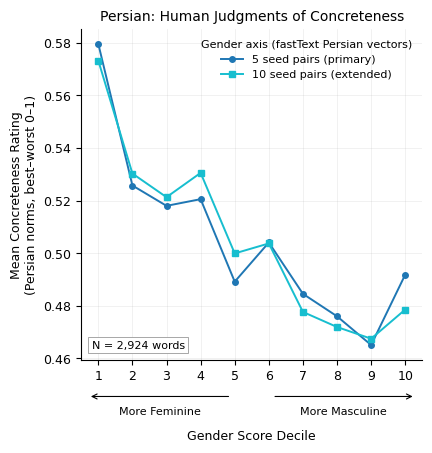

In [8]:
print("Mean concreteness by gender-score decile (1 = most feminine, 10 = most masculine):")
display(DEC.pivot_table(index="decile", columns="seeds", values="mean").round(2))
n_words = int(S[(S.seeds == "primary") & (S.specification == "all terms (no controls)")].n.iloc[0])
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(4.4, 4.3))
for pset, label, col, mk in [("primary", "5 seed pairs (primary)", "#1f77b4", "o"), ("extended", "10 seed pairs (extended)", "#17becf", "s")]:
    d = DEC[DEC.seeds == pset].sort_values("decile"); ax.plot(d.decile, d["mean"], marker=mk, ms=4, lw=1.4, color=col, label=label)
ax.set_xticks(range(1, 11)); ax.set_xlim(0.5, 10.5)
ax.set_ylabel(f"Mean Concreteness Rating\n({LANGNAME} norms, {SCALE})")
ax.set_title(f"{LANGNAME}: Human Judgments of Concreteness", fontsize=10); ax.grid(alpha=0.25, lw=0.5)
ax.text(0.03, 0.03, f"N = {n_words:,} words", ha="left", va="bottom", transform=ax.transAxes, fontsize=8, bbox=dict(boxstyle="square,pad=0.3", fc="white", ec="0.6", lw=0.6))
ax.legend(loc="best", fontsize=8, frameon=False, title=f"Gender axis (fastText {LANGNAME} vectors)", title_fontsize=8)
ax.set_xlabel("Gender Score Decile", labelpad=34)
ax.annotate("", xy=(0.02, -0.11), xytext=(0.44, -0.11), xycoords="axes fraction", arrowprops=dict(arrowstyle="->", lw=0.8))
ax.annotate("", xy=(0.98, -0.11), xytext=(0.56, -0.11), xycoords="axes fraction", arrowprops=dict(arrowstyle="->", lw=0.8))
ax.text(0.23, -0.14, "More Feminine", ha="center", va="top", transform=ax.transAxes, fontsize=8)
ax.text(0.77, -0.14, "More Masculine", ha="center", va="top", transform=ax.transAxes, fontsize=8)
for ext in ("png", "pdf"): fig.savefig(OUT / f"figS_{LANGNAME.lower()}_replication.{ext}", dpi=300, bbox_inches="tight")
plt.show()

## 5. Sensitivity to the seed pairs

In [9]:
prim, ext = SEEDS["primary"], SEEDS["extended"]
specs = {"primary set (5 pairs)": prim, "extended set (10 pairs)": ext}
for p in prim: specs[f"primary minus {p[0]}/{p[1]}"] = [q for q in prim if q != p]
for p in ext: specs[f"single pair {p[0]}/{p[1]}"] = [p]
for k, v in SEEDS.items():
    if k not in ("primary", "extended"):
        specs[f"{k} set"] = v
        for p in v:
            if p not in ext: specs[f"single pair {p[0]}/{p[1]}"] = [p]
PS = []
for label, pairs in specs.items():
    try: axis, used = gender_axis(lookup, pairs)
    except RuntimeError: continue
    g = score_terms(lookup, axis, norms.word.tolist()); ok = np.isfinite(g)
    r, p = stats.pearsonr(g[ok], norms.conc.values[ok]); lo, hi = fisher_ci(r, ok.sum())
    d = pd.DataFrame({"w": norms.word, "g": g}).dropna().sort_values("g")
    PS.append(dict(specification=label, n_pairs=len(used), r=r, ci_lo=lo, ci_hi=hi, p=p, n=int(ok.sum()),
                   most_female=", ".join(d.w.head(8)), most_male=", ".join(d.w.tail(8)[::-1])))
D = np.vstack([unit(unit(lookup(m)) - unit(lookup(f))) for m, f in ext if lookup(m) is not None and lookup(f) is not None])
U, s, Vt = np.linalg.svd(D, full_matrices=False); pc1 = Vt[0]; pc1 = pc1 if D.mean(0) @ pc1 > 0 else -pc1
g = score_terms(lookup, unit(pc1), norms.word.tolist()); ok = np.isfinite(g)
r, p = stats.pearsonr(g[ok], norms.conc.values[ok]); lo, hi = fisher_ci(r, ok.sum())
d = pd.DataFrame({"w": norms.word, "g": g}).dropna().sort_values("g")
PS.append(dict(specification=f"PC1 of extended set (var. expl. {s[0]**2/(s**2).sum():.2f}; loadings {np.round(D@pc1,2).tolist()})",
               n_pairs=len(D), r=r, ci_lo=lo, ci_hi=hi, p=p, n=int(ok.sum()), most_female=", ".join(d.w.head(8)), most_male=", ".join(d.w.tail(8)[::-1])))
PS = pd.DataFrame(PS)
PS[["specification", "n_pairs", "r", "ci_lo", "ci_hi", "n", "most_female", "most_male"]].round(3)

,specification,n_pairs,r,ci_lo,ci_hi,n,most_female,most_male
0,primary set (5 pairs),5,-0.194,-0.228,-0.158,2924,"زن, سکسی, پستان, بانو, ست, مو, لخت, گل","برادر, پدر, پسر, سردار, خان, شورید, جناب, مردی"
1,extended set (10 pairs),10,-0.208,-0.243,-0.173,2924,"ملکه, زن, سکسی, خانم, حامله, پستان, زنانه, مو","ملا, محمد, حاجی, آقا, خان, علی, برادر, سید"
2,primary minus مرد/زن,4,-0.170,-0.205,-0.135,2924,"پستان, بانو, خانم, سکسی, صدف, حامله, زنانه, خوشگل","برادر, پدر, شورید, فرماندهی, بن, جناب, ژنرال, جنگید"
3,primary minus پسر/دختر,4,-0.174,-0.209,-0.139,2924,"زن, سکسی, تی, گل, ست, تم, پستان, مو","برادر, مردی, سردار, پدر, جناب, خان, وفادار, مرد"
4,primary minus مردانه/زنانه,4,-0.187,-0.222,-0.152,2924,"زن, مو, ست, تی, سکسی, پستان, بانو, گل","برادر, پسر, پدر, شورید, مردی, ملا, جناب, خان"
5,primary minus پدر/مادر,4,-0.188,-0.222,-0.152,2924,"زن, مو, سکسی, در, تی, ست, گل, مد","برادر, سردار, پسر, جناب, خان, وفادار, مردی, شورید"
6,primary minus برادر/خواهر,4,-0.186,-0.221,-0.151,2924,"زن, مو, تی, گل, ست, کن, در, تم","پدر, پسر, مردی, سردار, وفادار, مرد, برادر, خان"
7,single pair مرد/زن,1,-0.102,-0.138,-0.066,2924,"زن, تی, سی, مو, پی, گل, فر, پد","مرد, مردی, پسر, روزی, افراد, صورتی, فرد, شخص"
8,single pair پسر/دختر,1,-0.157,-0.192,-0.121,2924,"دختر, خانم, بانو, زائر, ایرانی, خصوصی, چادر, تماشاگر","فرزند, پسر, پدر, برادر, بن, فرماندهی, شورید, بیامرز"
9,single pair مردانه/زنانه,1,-0.124,-0.160,-0.088,2924,"زنانه, پاشنه, صاف, سکسی, خوشگل, صدف, ناخن, مقعد","مردانه, سردار, قبیله, دشمن, قرعه, توپخانه, جنگید, ژنرال"


## 6. Secondary norm set (E-PLAN extrapolated scores, 85,716 words — machine-generated, a secondary check only)

In [10]:
S2 = DEC2 = None
if NORMS2.exists():
    norms2 = load_norms(NORMS2); norms2["logfreq"] = [logrank(w) for w in norms2.word]
    cov2 = norms2.word.map(lambda w: lookup(w) is not None).mean()
    print(f"{len(norms2):,} words; {cov2:.1%} with a vector")
    S2, DEC2, _, _ = run_all(norms2, label="[secondary] ")
    display(S2[S2.specification.isin(["all terms (no controls)", "excl. lexically gendered terms + seeds", "excl. 10% most gendered terms", "OLS: + log frequency"])].round(4))
    display(DEC2.pivot_table(index="decile", columns="seeds", values="mean").round(2))
else:
    print("secondary norms file not found - skipped")

85,700 words; 99.2% with a vector
[secondary] seeds=primary: 5/5 pairs; 85,007/85,700 words scored; held-out gendered pairs ordered male > female: 0.91 (n=11)
[secondary] seeds=extended: 10/10 pairs; 85,007/85,700 words scored; held-out gendered pairs ordered male > female: 0.91 (n=11)


,seeds,specification,r,ci_lo,ci_hi,p,rho,n,validation_accuracy,validation_pairs
0,primary,all terms (no controls),-0.1290,-0.1356,-0.1224,0.0,-0.1317,85007,0.9091,11
1,primary,excl. lexically gendered terms + seeds,-0.1316,-0.1383,-0.1250,0.0,-0.1336,83999,0.9091,11
3,primary,excl. 10% most gendered terms,-0.1417,-0.1487,-0.1348,0.0,-0.1407,76506,0.9091,11
5,primary,OLS: + log frequency,-0.1385,-0.1450,-0.1320,0.0,NaN,85007,0.9091,11
13,extended,all terms (no controls),-0.1469,-0.1535,-0.1403,0.0,-0.1482,85007,0.9091,11
14,extended,excl. lexically gendered terms + seeds,-0.1488,-0.1554,-0.1422,0.0,-0.1498,83999,0.9091,11
16,extended,excl. 10% most gendered terms,-0.1711,-0.1780,-0.1643,0.0,-0.1647,76506,0.9091,11
18,extended,OLS: + log frequency,-0.1442,-0.1507,-0.1378,0.0,NaN,85007,0.9091,11


seeds,extended,primary
decile,,
1,0.51,0.50
2,0.49,0.49
3,0.49,0.49
4,0.48,0.48
5,0.48,0.48
6,0.47,0.47
7,0.47,0.47
8,0.47,0.47
9,0.46,0.47


## 7. Save everything

In [11]:
S_out = S.copy(); S_out.insert(0, "model", VEC.name); S_out.insert(0, "language", LANGNAME)
S_out.to_csv(OUT / f"stats_{LANG}.csv", index=False)
DEC.to_csv(OUT / f"deciles_{LANG}.csv", index=False)
PS.to_csv(OUT / f"pole_sensitivity_{LANG}.csv", index=False)
scores.to_csv(OUT / f"scores_{LANG}.csv", index=False)
json.dump(seeds_used, open(OUT / f"seeds_{LANG}.json", "w", encoding="utf8"), ensure_ascii=False, indent=1)
if S2 is not None:
    S2.to_csv(OUT / f"stats_{LANG}_secondary.csv", index=False); DEC2.to_csv(OUT / f"deciles_{LANG}_secondary.csv", index=False)
print("written to", OUT)
for f in sorted(OUT.iterdir()): print("  ", f.name)

written to C:\Users\dguilb\Desktop\replication_folders\folders\persian replication\results_fa
   deciles_fa.csv
   deciles_fa_secondary.csv
   figS_persian_replication.pdf
   figS_persian_replication.png
   pole_sensitivity_fa.csv
   scores_fa.csv
   seeds_fa.json
   stats_fa.csv
   stats_fa_secondary.csv
